# Widgets

An adjustable playing card: rank and suit on rows of buttons, the hue and the corner radius on sliders and a
glow on a toggle. In a notebook `svg.interact` puts the controls beside the live card; `svg.sweep` turns
the same parameters into an animation.

    python 18_widgets.py                writes 18_card.svg, 18_suits.svg, 18_card_sweep.svg and 18_card_sweep.gif

In [1]:
import svgwriter as svg

The card is an ordinary drawing function. `@svg.widgets.controls` declares a control per parameter:
`Segmented` for a few choices, `Slider` for numbers and `Toggle` for on and off. The controls are plain
data, so `svg.interact`, `svg.sweep` and `svgwriter preview` all read the same declaration, and calling
the function directly still works.

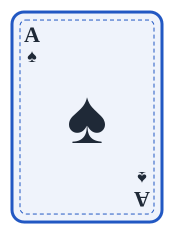

In [2]:
SUITS = {"♠": "#1f2937", "♥": "#dc2626", "♦": "#dc2626", "♣": "#1f2937"}
WIDTH, HEIGHT, MARGIN = 150, 210, 12


@svg.widgets.controls(
    rank=svg.widgets.Segmented(["A", "K", "Q", "J"]),
    suit=svg.widgets.Segmented(list(SUITS)),
    hue=svg.widgets.Slider(0, 360, step=1, format="{:.0f}°"),
    radius=svg.widgets.Slider(0, 24, step=0.5, label="corner radius"),
    glow=svg.widgets.Toggle(label="glow"),
)
def card(rank: str = "A", suit: str = "♠", hue: float = 220, radius: float = 12, glow: bool = False) -> svg.Document:
    """A playing card on a tinted face with a border in *hue*."""
    doc = svg.Document(WIDTH + 2 * MARGIN, HEIGHT + 2 * MARGIN)
    accent = svg.Color.from_hsl(hue, 0.7, 0.45)
    face = doc.rect(MARGIN, MARGIN, WIDTH, HEIGHT, rx=radius, fill=svg.Color.from_hsl(hue, 0.6, 0.96),
                    stroke=accent, stroke_width=3)
    if glow:
        face.filter = svg.filters.glow(6)
    doc.rect(MARGIN + 8, MARGIN + 8, WIDTH - 16, HEIGHT - 16, rx=max(radius - 6, 0), fill="none",
             stroke=accent, stroke_width=1, stroke_dasharray="4 3")
    ink = SUITS[suit]
    centre_x, centre_y = MARGIN + WIDTH / 2, MARGIN + HEIGHT / 2
    doc.text(suit, x=centre_x, y=centre_y + 26, font_size=76, text_anchor="middle", fill=ink)
    for turn in (0, 180):
        with doc.group(transform=f"rotate({turn} {centre_x} {centre_y})", fill=ink, text_anchor="middle"):
            doc.text(rank, x=MARGIN + 20, y=MARGIN + 30, font_size=22, font_weight="bold")
            doc.text(suit, x=MARGIN + 20, y=MARGIN + 50, font_size=18)
    return doc


card(rank="Q", suit="♥", hue=330, glow=True).save("18_card.svg")
card()

`svg.interact(card)` shows the controls beside the card and redraws it as they move (it needs the
`widget` extra: `pip install pysvgwriter[widget]`). The returned object keeps the current state:
`.values`, `.document`, `.save(path)` and `.code()`, a call to paste back into a script. Widgets only
run in a live notebook, so the cells after this one show the states as pictures.

In [3]:
view = svg.interact(card)
view.update(rank="K", suit="♦", hue=40, radius=4)
view.code()

Controls for rank, suit, hue, corner radius, glow; they appear while the notebook runs.

"card(rank='K', suit='♦', hue=40.0, radius=4.0, glow=False)"

One still per suit: the controls are only parameters, so the states are plain calls.

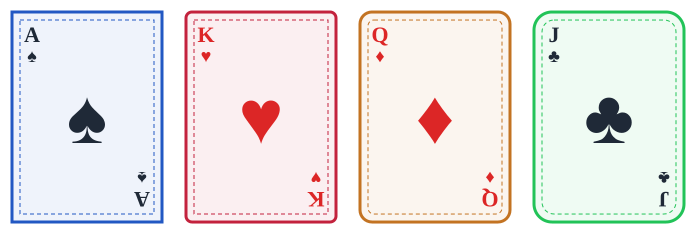

In [4]:
step = WIDTH + 2 * MARGIN
suits = svg.Document(len(SUITS) * step, HEIGHT + 2 * MARGIN)
for index, (rank, suit, hue) in enumerate(zip("AKQJ", SUITS, (220, 350, 30, 140), strict=True)):
    face = card(rank=rank, suit=suit, hue=hue, radius=6 * index).root
    face.x = index * step
    suits += face
suits.save("18_suits.svg")
suits

`svg.sweep` steps parameters over time: `(start, end)` runs smoothly, a list or an option control steps
through its values. The result is a `Scene`, so it saves as baked SMIL (the SVG below plays in a
browser), as a GIF without ffmpeg, as MP4 or as PowerPoint.

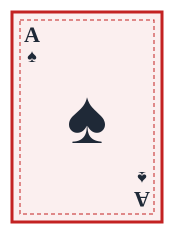

In [5]:
sweep = svg.sweep(card, hue=(0, 360), radius=(0, 24), suit=list(SUITS), dur=4, fps=12, ease="ease-in-out")
sweep.save("18_card_sweep.svg")
sweep.save("18_card_sweep.gif")
sweep